# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO non-branching and Gate 3 = NA, the branching-only `04_correlation` / `05_modules` notebooks are not produced; the unconditional EMT-TF step is the last notebook.)* We derive the informative EMT-TFs from detectable expression along pseudotime. In AML blasts the canonical epithelial factors are silent — the readout is honest about what is expressed.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 96881 | pseudotime range 0.0 -> 7.35


### Derive the end-specific EMT-TFs (data-driven)
Fraction expressing, early-vs-late means, and Spearman rho vs pseudotime; gated on >3% expression; FOXC/PRRX families included.

In [4]:
# Derive the end-specific EMT-TFs (data-driven), gated on detectable expression. For each
# candidate TF: fraction of cells expressing it, mean at the early (root) third vs late (terminus)
# third of pseudotime, and Spearman rho vs pseudotime. We include the FOXC/PRRX mesenchymal families,
# not only Snail/Zeb/Twist (Kurten lesson). Only TFs expressed in >3% of cells qualify.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('candidate TFs present in data:', present)
print('candidate TFs absent (filtered/unexpressed):', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print(f'\nexpressed TFs (>3% of cells): {ok.TF.tolist()}')
# In AML blasts the canonical epithelial EMT-TFs are essentially silent; ZEB2 (a hematopoietic
# transcriptional regulator) is the only detectably-expressed factor. Show the informative TF(s).
tfs = ok.sort_values('rho_vs_t')['TF'].tolist()
print('informative EMT-TF(s):', tfs)

candidate TFs present in data: ['SNAI1', 'ZEB1', 'ZEB2', 'TWIST2']
candidate TFs absent (filtered/unexpressed): ['SNAI2', 'TWIST1', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.051       0.032      0.034    -0.009 LATE(terminus)
  ZEB1      0.005       0.003      0.003    -0.003 LATE(terminus)
 SNAI1      0.000       0.000      0.000    -0.002 LATE(terminus)
TWIST2      0.000       0.000      0.000     0.003 LATE(terminus)

expressed TFs (>3% of cells): ['ZEB2']
informative EMT-TF(s): ['ZEB2']


### EMT-TF expression overlay (deliverable)
House style, categorical overlay of thresholded expressers on a grey manifold.

ZEB2: 5.1% expressing; 1241 shown (upper quartile), mean pseudotime of shown cells = 0.59 (all cells = 0.52)
saved expression.pdf


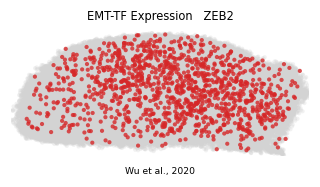

In [5]:
# EMT-TF expression overlay (deliverable). House style: figsize=(3.5,1.5), pseudotime left->right,
# categorical overlay of thresholded expressers (upper quartile among expressers) on a grey manifold.
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
palette = ['tab:red','tab:blue','tab:green','tab:orange']
show_tfs = tfs[:min(2,len(tfs))] if len(tfs)>=2 else tfs
colors = {g: palette[i] for i,g in enumerate(show_tfs)}
thr = {}
for g in show_tfs:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in show_tfs}
order = sorted(show_tfs, key=lambda g: -int(sel[g].sum()))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = '  '.join(f'{g}' for g in show_tfs)
ax.set_title(f'EMT-TF Expression   {lbl}', size=7.5)
ax.text(.5,-.14,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in show_tfs:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')